In [ ]:
from scipy.stats import uniform
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
file = open("vectors.txt","r")
data = file.readlines()
Nlines = len(data)
print("Nlines = ",Nlines)

Nlines =  278


In [ ]:
wfile = open("words_idx.txt","r")
words = wfile.readlines()
Nwords = len(words)
print("Nwords = ",Nwords)

Nwords =  18446


In [ ]:
# Constructing A matrix
Ndocs = int(Nlines/2)
A = np.zeros((Ndocs,Nwords))
Doc_idx = np.zeros((Ndocs,))
for j in range(Ndocs):
    Doc_idx = data[2*j]
    line = data[2*j+1]
    line = line.split()
    content = [eval(i) for i in line][1:] # Ignoring the first number in the line
    w_idx   = np.array(content[0::2])-1   # make indices start from 0
    w_count = content[1::2]
    A[j,w_idx] = 1

In [16]:
iter_max  = 200
rnd_state = 0
k         = 250
W0        = uniform.rvs(size=(Ndocs,k), random_state=rnd_state)
H0        = uniform.rvs(size=(k,Nwords), random_state=rnd_state)

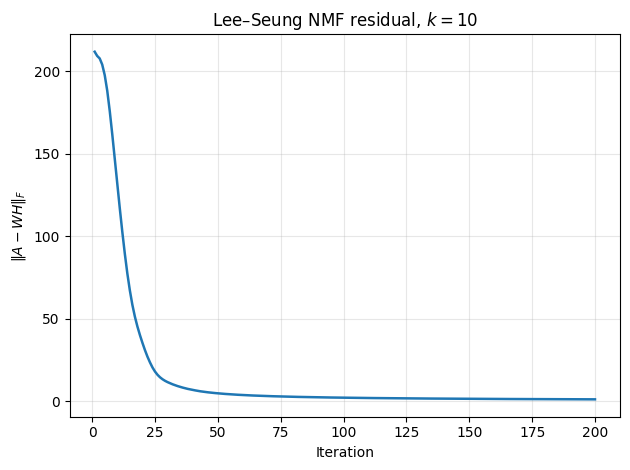

iteration   1: ||A - WH||_F = 211.6916
iteration  10: ||A - WH||_F = 131.5754
iteration  20: ||A - WH||_F = 35.2642
iteration  30: ||A - WH||_F = 11.4397
iteration  50: ||A - WH||_F = 4.6528
iteration 100: ||A - WH||_F = 2.0076
iteration 200: ||A - WH||_F = 1.0098


In [17]:
# Write code for Lee and Seung's Multicative NMF Algorithm
# Also evaluate the Frobenius norm of the residual after each iteration
# and save it to an array. Plot this array to see how the residual
# drop with each subsequent iteration

resid = -1.0*np.ones(iter_max)

W = W0
H = H0

for i in range(iter_max):
  W = W/(W@H@H.T)*(A@H.T)
  H = H/(W.T@W@H)*(W.T@A)
  resid[i] = np.linalg.norm(A-W@H,ord='fro')

plt.figure()
plt.plot(np.arange(1, iter_max + 1), resid, lw=1.8)
plt.xlabel("Iteration")
plt.ylabel(r"$\|A - WH\|_F$")
plt.title("Lee–Seung NMF residual, $k=10$")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("nmf_residual.png", dpi=200)
plt.show()

for i in [1, 10, 20, 30, 50, 100, 200]:
    print(f"iteration {i:3d}: ||A - WH||_F = {resid[i-1]:.4f}")

In [11]:
# For each row of H, find the r largest
# entries and plot the words they correspond to
r = 12
for j in range(k):
    ind = np.argsort(H[j,:])[::-1][:r]
    print(H[j,ind])
    if len(ind.tolist()) > 0:
        for i in range(len(ind.tolist())):
            print(ind[i]+1,words[ind[i]])

[8.35106969 8.35039689 8.28151224 8.09539612 8.05990942 8.05258787
 8.0512188  8.04565169 8.03484569 8.02275216 8.02181859 8.01265629]
379 379 2003

652 652 links

600 600 page

52 52 gif

154 154 web

77 77 miami

113 113 south

8 8 the

1 1 florida

103 103 west

116 116 city

18 18 and

[20.96562654 19.36423271 19.2851619  19.2811266  19.08710297 18.908529
 18.86675559 18.7808345  18.71107543 18.70920449 18.6027567  18.54052284]
559 559 into

553 553 would

428 428 there

376 376 next

420 420 people

514 514 good

732 732 they

586 586 then

592 592 come

642 642 well

443 443 like

419 419 when

[10.03634438  9.94649939  9.84883859  9.70355209  9.58295663  9.53975488
  9.50942617  9.35165458  9.31756247  9.28980491  9.27424614  9.26749119]
564 564 atmosphere

484 484 great

233 233 education

612 612 child

551 551 club

1215 1215 calendar

244 244 each

823 823 educational

113 113 south

664 664 creating

286 286 community

836 836 members

[59.61831977 59.35014002 59.12097255 5

In [13]:
from sklearn.decomposition import TruncatedSVD

A_10 = TruncatedSVD(n_components=10).fit_transform(A)
residual = (np.linalg.norm(A-A-10,ord='fro'))/np.linalg.norm(A,ord='fro')

print('Frobenius error of rank 10 SVD approximation: ' + str(residual))

Frobenius error of rank 10 SVD approximation: 69.35903562429743
